In [1]:

# Day 25: Improving DAS Reconstruction

## Objective
Improve the temporal sampling accuracy of Delay-and-Sum (DAS) reconstruction using linear interpolation.

## Method
Compare nearest-sample DAS with interpolated DAS.

## Output
Save the reconstructed image and numerical results in the outputs folder.


SyntaxError: invalid syntax (4017612195.py, line 4)

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Libraries loaded!")
print("Output folder is ready:", output_dir)


Libraries loaded!
Output folder is ready: ..\outputs


In [3]:

# Speed of sound in tissue (m/s)
c = 1500.0

# Sampling frequency (Hz)
fs = 10e6

# Number of sensors
num_sensors = 32

# Sensor positions (m)
sensor_x = np.linspace(-0.03, 0.03, num_sensors)
sensor_y = np.zeros(num_sensors)

# True source position (m)
source_x = 0.005
source_y = 0.020

# Time array (s)
duration = 60e-6
time = np.arange(0, duration, 1/fs)

print("Number of sensors:", num_sensors)
print("Sampling frequency:", fs / 1e6, "MHz")
print("Number of time samples:", len(time))
print(f"True source: ({source_x*1000:.2f}, {source_y*1000:.2f}) mm")


Number of sensors: 32
Sampling frequency: 10.0 MHz
Number of time samples: 600
True source: (5.00, 20.00) mm


In [4]:

# Calculate distance from each sensor to the source
distances = np.sqrt(
    (sensor_x - source_x)**2 +
    (sensor_y - source_y)**2
)

# Calculate signal arrival times
arrival_times = distances / c

# Create synthetic sensor signals
signals = np.zeros((num_sensors, len(time)))

pulse_width = 1.5e-6

for i in range(num_sensors):
    signals[i] = np.exp(
        -0.5 * ((time - arrival_times[i]) / pulse_width)**2
    )

print("Signal matrix shape:", signals.shape)
print(
    "First sensor arrival time:",
    arrival_times[0] * 1e6,
    "microseconds"
)


Signal matrix shape: (32, 600)
First sensor arrival time: 26.874192494328494 microseconds


In [5]:

image_size = 100

x_grid = np.linspace(-0.03, 0.03, image_size)
y_grid = np.linspace(0.0, 0.04, image_size)

X, Y = np.meshgrid(x_grid, y_grid)

print("Image grid shape:", X.shape)
print("X range (mm):", x_grid.min()*1000, "to", x_grid.max()*1000)
print("Y range (mm):", y_grid.min()*1000, "to", y_grid.max()*1000)


Image grid shape: (100, 100)
X range (mm): -30.0 to 30.0
Y range (mm): 0.0 to 40.0


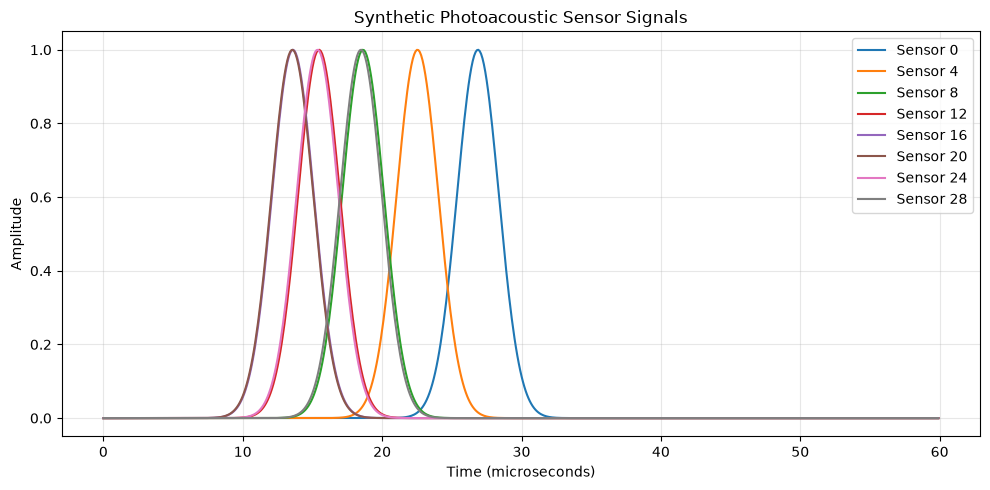

In [6]:

plt.figure(figsize=(10, 5))

for i in range(0, num_sensors, 4):
    plt.plot(time * 1e6, signals[i], label=f"Sensor {i}")

plt.xlabel("Time (microseconds)")
plt.ylabel("Amplitude")
plt.title("Synthetic Photoacoustic Sensor Signals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day25_synthetic_signals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [7]:

def delay_and_sum_interpolated(
    signals, time, sensor_x, sensor_y, X, Y, c
):
    num_sensors = signals.shape[0]
    image = np.zeros(X.shape, dtype=float)

    for i in range(num_sensors):
        distance = np.sqrt(
            (X - sensor_x[i])**2 +
            (Y - sensor_y[i])**2
        )

        tof = distance / c

        sensor_contribution = np.interp(
            tof.ravel(),
            time,
            signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += sensor_contribution

    return image


In [8]:

interpolated_image = delay_and_sum_interpolated(
    signals=signals,
    time=time,
    sensor_x=sensor_x,
    sensor_y=sensor_y,
    X=X,
    Y=Y,
    c=c
)

print("Reconstruction complete!")
print("Image shape:", interpolated_image.shape)
print("Maximum intensity:", interpolated_image.max())


Reconstruction complete!
Image shape: (100, 100)
Maximum intensity: 31.897689381836166


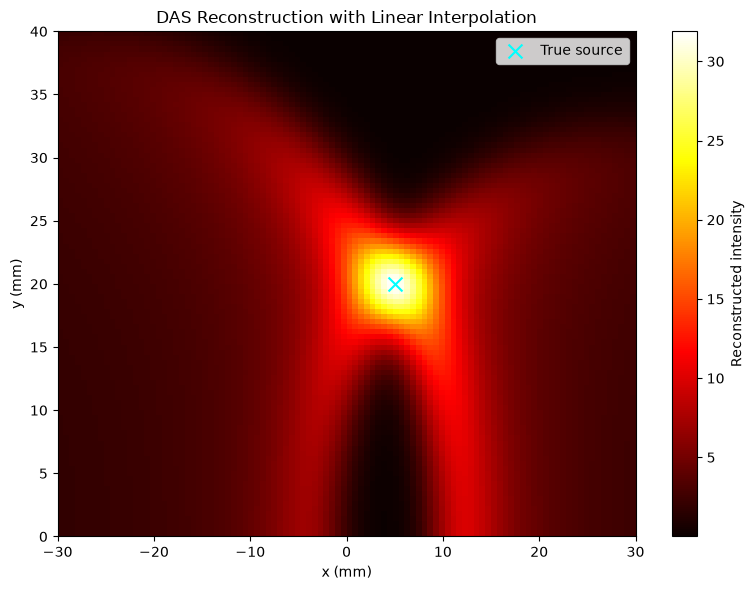

Image saved to: ..\outputs\day25_das_interpolated.png


In [9]:

plt.figure(figsize=(8, 6))

plt.imshow(
    interpolated_image,
    extent=[
        x_grid.min() * 1000,
        x_grid.max() * 1000,
        y_grid.min() * 1000,
        y_grid.max() * 1000
    ],
    origin="lower",
    aspect="auto",
    cmap="hot"
)

plt.colorbar(label="Reconstructed intensity")

plt.scatter(
    [source_x * 1000],
    [source_y * 1000],
    marker="x",
    color="cyan",
    s=100,
    label="True source"
)

plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.title("DAS Reconstruction with Linear Interpolation")
plt.legend()
plt.tight_layout()

plt.savefig(
    output_dir / "day25_das_interpolated.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Image saved to:", output_dir / "day25_das_interpolated.png")


In [10]:

# Find the pixel with the highest intensity
estimated_index = np.unravel_index(
    np.argmax(interpolated_image),
    interpolated_image.shape
)

# Estimated source position
estimated_x = X[estimated_index]
estimated_y = Y[estimated_index]

# Calculate localization error
error = np.sqrt(
    (estimated_x - source_x)**2 +
    (estimated_y - source_y)**2
)

print(
    f"True source: "
    f"({source_x*1000:.2f}, {source_y*1000:.2f}) mm"
)

print(
    f"Estimated source: "
    f"({estimated_x*1000:.2f}, {estimated_y*1000:.2f}) mm"
)

print(f"Localization error: {error*1000:.3f} mm")


True source: (5.00, 20.00) mm
Estimated source: (5.15, 19.80) mm
Localization error: 0.253 mm


In [11]:

import json

results = {
    "method": "DAS with linear interpolation",
    "num_sensors": int(signals.shape[0]),
    "image_shape": list(interpolated_image.shape),
    "true_source_mm": [
        float(source_x * 1000),
        float(source_y * 1000)
    ],
    "estimated_source_mm": [
        float(estimated_x * 1000),
        float(estimated_y * 1000)
    ],
    "localization_error_mm": float(error * 1000)
}

results_path = output_dir / "day25_das_results.json"

with open(results_path, "w") as file:
    json.dump(results, file, indent=4)

print("Results saved to:", results_path)
print("\nResults:")
print(json.dumps(results, indent=4))


Results saved to: ..\outputs\day25_das_results.json

Results:
{
    "method": "DAS with linear interpolation",
    "num_sensors": 32,
    "image_shape": [
        100,
        100
    ],
    "true_source_mm": [
        5.0,
        20.0
    ],
    "estimated_source_mm": [
        5.15151515151515,
        19.797979797979796
    ],
    "localization_error_mm": 0.2525252525252526
}
